# 16. Diagnóstico da série: sazonalidade, estacionariedade e diferenças

**Objetivo e requisitos.** Antes de comparar modelos, descobrir se a série tem ciclo e se precisa de diferenças, e deixar a busca usar essas respostas sem vazamento. Referências: Wang, Smith e Hyndman (2006) para a força sazonal, Hyndman e Khandakar (2008) para a escolha automática de diferenças e ordens, e as duas regras de caracterização do projeto de replicação (ADF; força da STL sobre Box-Cox). Vale nas variantes A e B. Extras: `stats` (testes e STL) e `plot`.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import pandas as pd

import autohybts
from autohybts import AutoHybridExperiment
from autohybts.datasets import get_data

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
print("AutoHybTS", autohybts.__version__)

AutoHybTS 1.0.0rc2


## 1. Dados e protocolo

Duas séries sintéticas de 500 dias: `synthetic_daily` (tendência, ciclo semanal e ruído AR(1)) e `white_noise_daily` (nível mais ruído branco, o controle negativo). Num painel, cada série guarda o seu teste selado (`fh=14` pontos); os diagnósticos leem só o histórico de desenvolvimento.

In [2]:
y = get_data("synthetic_daily", n=500)
noise = get_data("white_noise_daily", n=500)
panel = AutoHybridExperiment(fh=14, session_id=SEED).fit({"synthetic": y, "noise": noise})
panel.splits.head()

layer train_start     origin first_target last_target  \
series_id fold_id                                                            
synthetic search-0  search  2024-01-01 2024-10-16   2024-10-17  2024-10-30   
          search-1  search  2024-01-01 2024-10-30   2024-10-31  2024-11-13   
          search-2  search  2024-01-01 2024-11-13   2024-11-14  2024-11-27   
          search-3  search  2024-01-01 2024-11-27   2024-11-28  2024-12-11   
          search-4  search  2024-01-01 2024-12-11   2024-12-12  2024-12-25   

                    n_train  horizon  
series_id fold_id                     
synthetic search-0      290       14  
          search-1      304       14  
          search-2      318       14  
          search-3      332       14  
          search-4      346       14

## 2. Exploração causal

Primeiro a regra da biblioteca: força sazonal da decomposição clássica e teste de Friedman com os ciclos como blocos, para os períodos 7 e 30.

In [3]:
panel.seasonality_report(periods=[7, 30]).drop(columns="reason").round(3)

n_cycles  strength  autocorrelation  p_value  seasonal  \
series_id period                                                           
synthetic 7         69.429     0.877            0.877    0.000      True   
          30        16.200     0.014           -0.157    1.000     False   
noise     7         69.429     0.021            0.091    0.722     False   
          30        16.200     0.033           -0.046    0.991     False   

                  seasonal_differences  
series_id period                        
synthetic 7                          1  
          30                         0  
noise     7                          0  
          30                         0

Depois as duas regras do projeto de replicação: ADF para a estacionariedade e a ordem `d`; para as séries não estacionárias, força da STL robusta sobre a série Box-Cox e a categoria.

In [4]:
columns = ["adf_stat_d0", "adf_pvalue_d0", "adf_pvalue_d1", "kpss_pvalue_d0", "diff_order"]
columns += ["fs_7", "fs_30", "dominant_period", "category"]
panel.characterize(periods=[7, 30])[columns].round(3)

,adf_stat_d0,adf_pvalue_d0,adf_pvalue_d1,kpss_pvalue_d0,diff_order,fs_7,fs_30,dominant_period,category
series_id,,,,,,,,,
synthetic,-0.314,0.924,0.0,0.01,1,0.852,0.101,7.0,seasonal
noise,-19.916,0.000,0.0,0.10,0,NaN,NaN,NaN,stationary


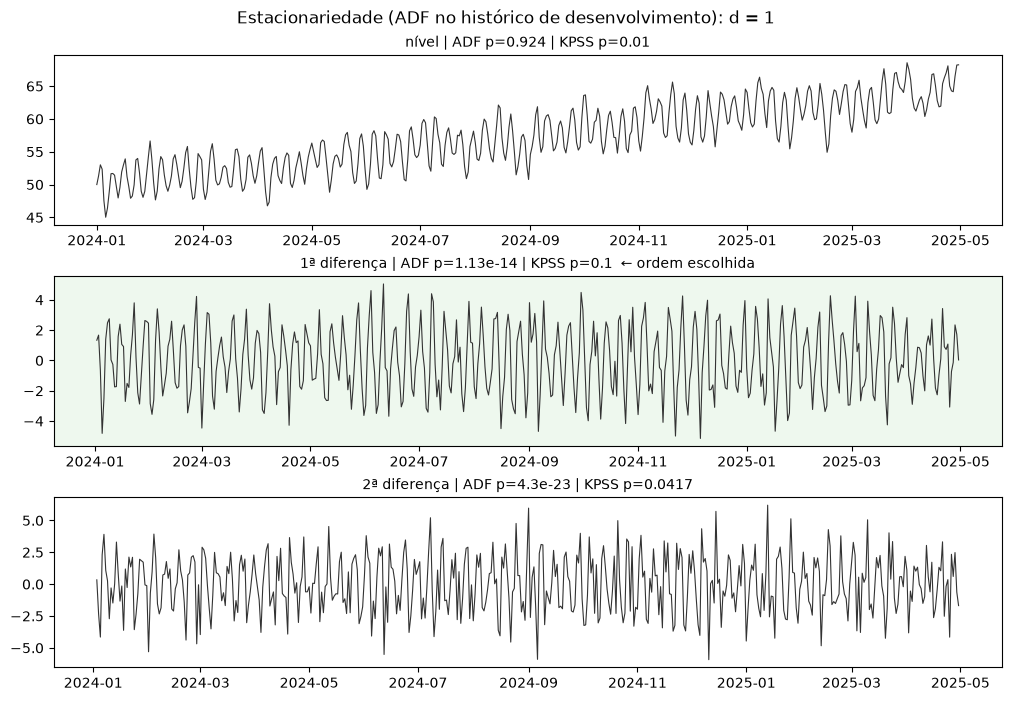

In [5]:
panel.plot_data("stationarity", series_id="synthetic")

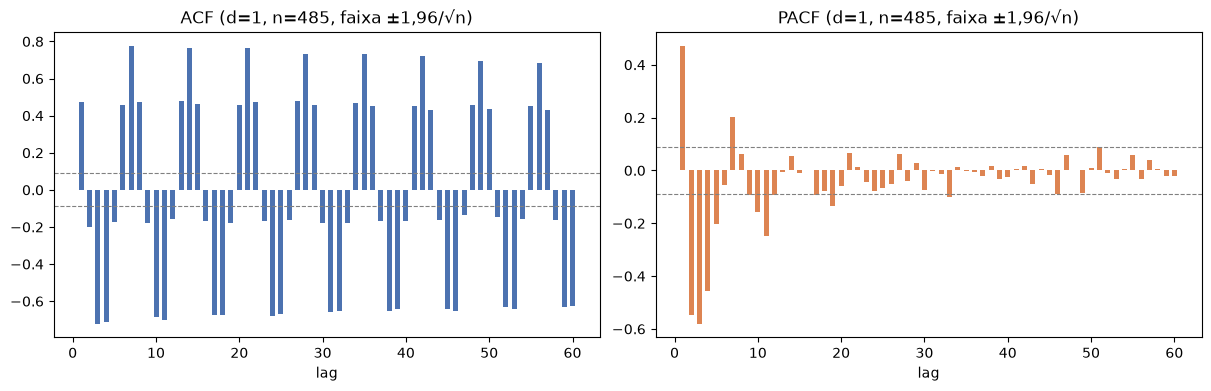

In [6]:
panel.plot_data("acf_pacf", series_id="synthetic")

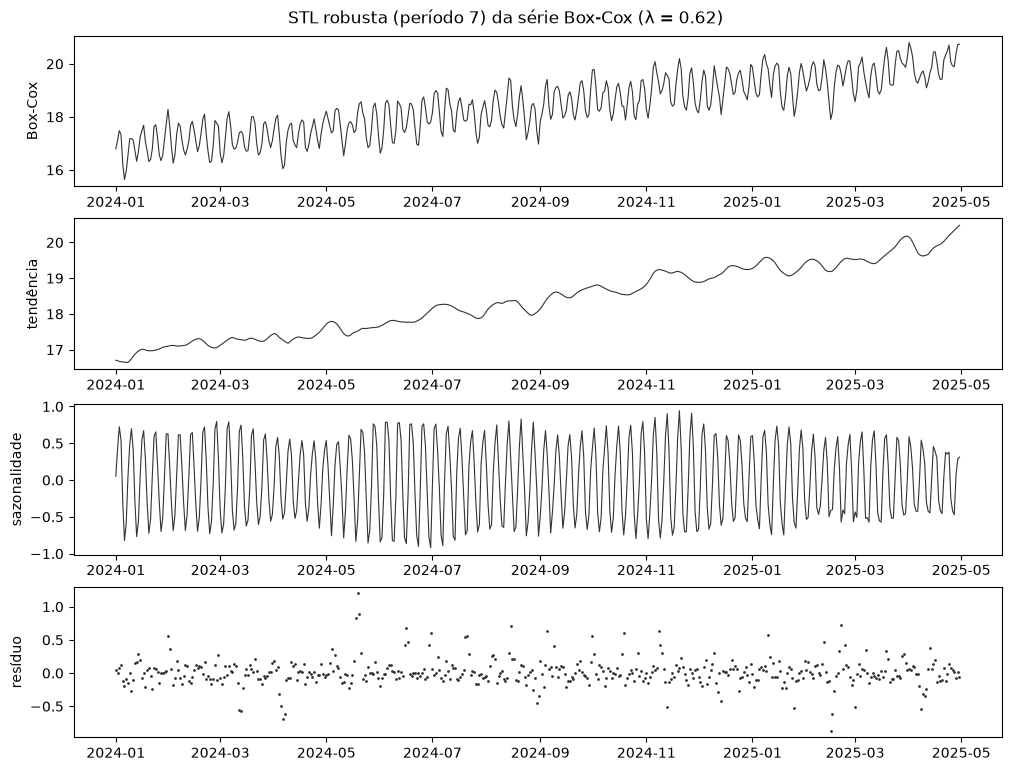

In [7]:
panel.plot_data("decomposition", series_id="synthetic")

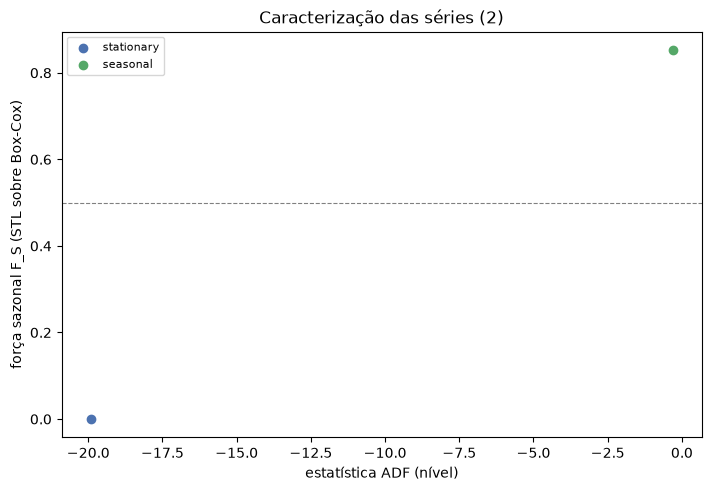

In [8]:
panel.plot_characterization(periods=[7, 30])

## 3. Controles e modelos propostos

Mesmas origens (`fold=3`, para o exemplo rodar em poucos minutos; a regra de aceite foi calibrada para 7) e mesma métrica (MASE). Controles: `seasonal_naive` e `exponential_smoothing` sazonal. Propostos: `sarima` e o KNN sobre lags com `differencing="auto"`, contra o mesmo KNN em nível. Com `seasonal_period="auto"`, o experimento testa o ciclo no treino da primeira origem antes de passar o período aos modelos.

In [9]:
exp = AutoHybridExperiment(fh=14, fold=3, seasonal_period="auto", session_id=SEED).fit(y)
print("período da busca:", exp.search_period_)
exp.seasonality_.drop(columns="reason").round(3)

período da busca: 7


,period,n_cycles,strength,autocorrelation,p_value,seasonal,seasonal_differences,keep_period
series_id,,,,,,,,
__single__,7,57.429,0.882,0.875,0.0,True,1,True


In [10]:
candidates = {
    "seasonal_naive": {"season_length": 7},
    "exponential_smoothing": {"season_length": 7},
    "arima": {},
    "sarima": {"season_length": 7},
    "knn": {"lags": 7},
    "knn (differencing=auto)": {"lags": 7, "differencing": "auto", "season_length": 7},
}
rows = []
for label, params in candidates.items():
    started = time.perf_counter()
    result = exp.create_model(label.split(" ")[0], **params)
    rows.append(
        {"model": label, "MASE": result.metrics["MASE"], "seconds": time.perf_counter() - started}
    )
table = pd.DataFrame(rows).set_index("model").sort_values("MASE")
table.round(3)

,MASE,seconds
model,,
sarima,0.867,152.516
arima,0.896,17.772
exponential_smoothing,0.897,1.991
knn (differencing=auto),1.189,0.119
seasonal_naive,1.405,0.007
knn,1.412,0.471


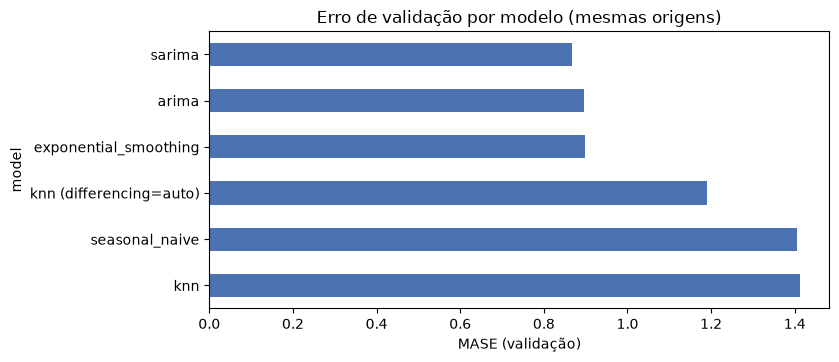

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.6))
table["MASE"].plot.barh(ax=ax, color="#4C72B0")
ax.invert_yaxis()
ax.set_xlabel("MASE (validação)")
ax.set_title("Erro de validação por modelo (mesmas origens)")
plt.show()

## 4. Busca e seleção

A opção de experimento `differencing="auto"` repassa a escolha de diferenças a todos os modelos sobre lags embutidos da busca. Orçamento `smoke` para o exemplo; a busca usa `V_search` e a decisão, `V_select`.

In [12]:
search = AutoHybridExperiment(
    fh=14,
    fold=3,
    budget="smoke",
    differencing="auto",
    base_models=["seasonal_naive", "arima", "linear", "knn"],
    session_id=SEED,
).fit(y)
result = search.compare_models()
result.leaderboard.head(8)

,name,model,family,strategy,base,corrector,residual_source,window,alpha,mean_rank,...,MAE,RMSE,sMAPE,coverage,n_units,n_failed,n_skipped,fit_seconds,predict_seconds,is_champion
candidate_id,,,,,,,,,,,,,,,,,,,,,
7fd291011a690f1edb92d697b682dc473f7cfc3303579db95482c16613ca1af3,arima,arima,statistical,standalone,arima,NaN,NaN,NaN,NaN,1.0,...,1.365299,1.660872,0.022214,1.0,3,0,0,0.096114,0.025180,True
5eee0fd04c5d031149c009afa0f6ef16ed0881ef9bff723be77cb371c98c48f2,arima-linear,"arima + linear [w=7, alpha=0.5, historical_oof...",residual,residual_additive,arima,linear,historical_oof_1step,7.0,0.5,2.0,...,1.367917,1.668751,0.022257,1.0,3,0,0,5.073315,0.015492,False
d4f7168351c24eb920adc1c4cbb7e77e4fc86e4566a282bb32be039cc75d5a12,linear,"linear(differencing=auto, differencing_test=kp...",linear,standalone,linear,NaN,NaN,NaN,NaN,3.0,...,1.518704,1.837356,0.024748,1.0,3,0,0,0.025746,0.020170,False
884a91bac6de8a3eafc9e452f7f1cd1a88d42e1fe82804d9e84e2f1b1d1b5a32,linear-linear,"linear(differencing=auto, differencing_test=kp...",residual,residual_additive,linear,linear,historical_oof_1step,7.0,0.5,4.0,...,1.527718,1.822845,0.024888,1.0,3,0,0,0.337184,0.008152,False
470ea3be8ccbb0e2784c326810af859d05ed24ac33f81dfcba29252bb43e03a7,knn,"knn(differencing=auto, differencing_test=kpss,...",kernel,standalone,knn,NaN,NaN,NaN,NaN,5.0,...,1.652017,2.048472,0.026839,1.0,3,0,0,0.020240,0.074945,False
fd77544caef0cc3d0acb5b33cadb1f8244ab1e37a4bff9a7ebd3d4b3b3b1e2f2,linear-linear,"linear(differencing=auto, differencing_test=kp...",residual,residual_additive,linear,linear,historical_oof_multistep,7.0,0.5,6.0,...,1.732915,2.074141,0.028340,1.0,3,0,0,0.137594,0.007880,False
f80012db7c7cd35e1e991dad0572130d03e3543ad308fb5f9e4a8aa888b20767,arima-linear,"arima + linear [w=7, alpha=0.5, historical_oof...",residual,residual_additive,arima,linear,historical_oof_multistep,7.0,0.5,7.0,...,1.845696,2.191862,0.030163,1.0,3,0,0,5.176033,0.015782,False
d90528888825a4459816afbcf249ff909747924f0a2bbaa6e09d027e31342238,seasonal_naive,seasonal_naive(season_length=7),statistical,standalone,seasonal_naive,NaN,NaN,NaN,NaN,8.0,...,1.920807,2.313453,0.031680,1.0,3,0,0,0.000291,0.000448,False


## 5. Resultados e gráficos

A cadeia de decisões e as previsões do campeão nas origens de validação.

In [13]:
result.decisions[["family", "champion_before", "challenger", "accepted", "median_gain", "win_rate"]]

,family,champion_before,challenger,accepted,median_gain,win_rate
0,linear,arima,linear,False,-0.400123,0.000000
1,kernel,arima,knn,False,-0.357053,0.000000
2,residual,arima,arima-linear,False,0.027968,0.666667


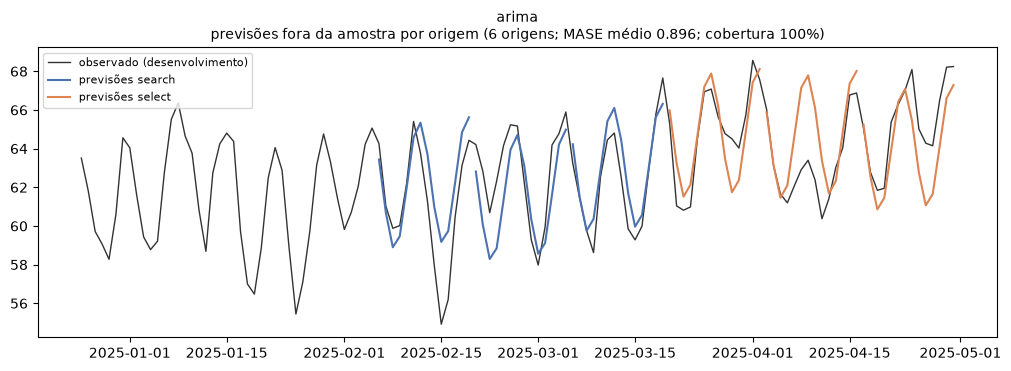

In [14]:
search.plot_model(result.best, "cv_forecasts")

## 6. Diagnóstico e limites

No ruído branco, `seasonal_period="auto"` derruba o período (os modelos sazonais ficam `SKIPPED`). Com poucos ciclos no treino da primeira origem, o teste não tem poder e o período da frequência fica: abaixo, 60 meses de ruído.

In [15]:
auto_noise = AutoHybridExperiment(fh=14, seasonal_period="auto", session_id=SEED).fit(noise)
monthly = pd.Series(noise.to_numpy()[:60], index=pd.date_range("2016-01-01", periods=60, freq="MS"))
short = AutoHybridExperiment(fh=6, fold=2, seasonal_period="auto", session_id=SEED).fit(monthly)
cases = {"white_noise_daily (500 d)": auto_noise, "noise, 60 months": short}
pd.DataFrame(
    {
        name: {
            "search_period_": case.search_period_,
            "n_cycles": case.seasonality_["n_cycles"].iloc[0],
            "p_value": case.seasonality_["p_value"].iloc[0],
        }
        for name, case in cases.items()
    }
).T.round(3)

,search_period_,n_cycles,p_value
white_noise_daily (500 d),1.0,41.429,0.895
"noise, 60 months",12.0,2.500,NaN


## 7. Avaliação externa

Uma única leitura do teste selado, depois de congelar a escolha.

In [16]:
final = search.finalize_model(result.best)
external = search.evaluate_external(final)
external.metrics.round(3)

,MASE,MAE,RMSE,sMAPE
model,,,,
arima,0.795,1.244,1.733,0.019


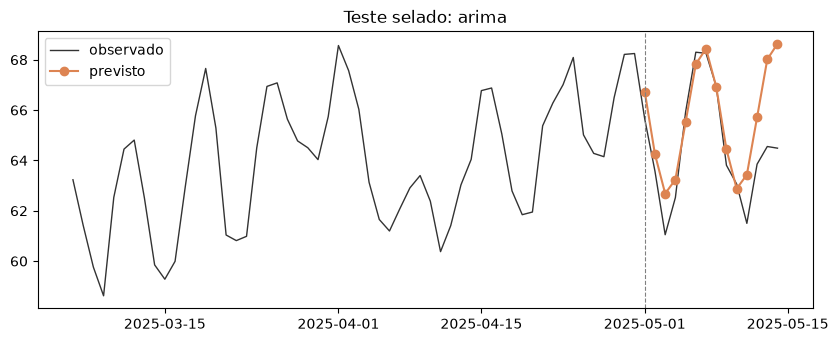

In [17]:
recent = y.iloc[-70:]
predictions = external.predictions
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(recent.index, recent.to_numpy(), color="#333333", linewidth=1, label="observado")
ax.plot(predictions.index, predictions["y_pred"], color="#DD8452", marker="o", label="previsto")
ax.axvline(predictions.index[0], color="gray", linestyle="--", linewidth=0.8)
ax.set_title(f"Teste selado: {final.spec.label}")
ax.legend()
plt.show()

## 8. Leitura

* **Diagnóstico.** Na `synthetic_daily`, o ciclo semanal é claro pelas duas regras: força 0,88 e Friedman p < 0,001 pela regra da biblioteca; ADF p = 0,92 em nível (não estacionária), estacionária com uma diferença, `F_S` = 0,85 na STL sobre Box-Cox e categoria `seasonal` pela regra da replicação. O período 30 não aparece (força 0,01 e 0,10). O ruído branco sai estacionário (ADF p < 0,001), sem ciclo (p = 0,72).
* **Modelos nas mesmas 6 origens.** O `sarima` teve o menor erro (MASE 0,867), seguido de `arima` (0,896) e `exponential_smoothing` (0,897), com custo bem maior: cerca de 2 min, contra 11–18 s do `arima` e menos de 2 s do ETS. Com `differencing="auto"`, o KNN foi de 1,412 para 1,189: a diferença escolhida no treino tirou a tendência que os vizinhos não extrapolam. O `seasonal_naive` (1,405) ficou entre os piores.
* **Busca e seleção.** Com `differencing="auto"` nos modelos sobre lags e orçamento `smoke`, o campeão foi o `arima`. Os desafiantes foram recusados: `linear` e `knn` perderam em todas as unidades (ganho mediano −40 % e −36 %), e `arima-linear` venceu em 67 % das unidades (acima dos 60 % exigidos), mas com ganho mediano de 2,8 %, abaixo dos 5 %. Com `fold=3`, a regra tem só 3 unidades por comparação, menos que as 7 da calibração.
* **Limites.** No ruído branco, `seasonal_period="auto"` passou o período a 1 (p = 0,90 com 41 ciclos). Com 60 meses e `fh=6`, o treino da primeira origem tinha 2,5 ciclos: sem teste, e o período 12 ficou, como manda a regra dos 6 ciclos.
* **Teste selado.** Lido uma vez, depois da escolha: MASE 0,795 para o `arima`, um só bloco de 14 dias, sem margem para comparar estruturas.